In [1]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.data_generator import DataGenerator
from src.missingness_generator import MissingnessGenerator
from src.utils import true_quantile

import numpy as np
import matplotlib.pyplot as plt
import torch

from src.metrics import energy_distance

from joblib import Parallel, delayed

In [2]:
kk = (1,20)

In [3]:
def example2_logistic(n=2000):
    U = torch.rand(n, 2)
    X = torch.special.logit(U)
    mg = MissingnessGenerator(U)
    M = mg.example2(U[:,0], U[:, 1])
    Xtest = torch.special.logit(torch.rand(n, 2))
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [4]:
n = 2000
U = torch.rand(n, 2)
X = torch.special.logit(U)
mg = MissingnessGenerator(U)
M = mg.example2(U[:,0], U[:, 1])
Xtest = torch.special.logit(torch.rand(n, 2))
gmm = GaussianMixtureMAR(kk)
gmm.fit(X, M)
Xtilde = gmm.sample(n)[0]

In [5]:
# Standard logistic PDF
x = np.linspace(-4, 4, 500)
pdf = np.exp(-x) / (1 + np.exp(-x))**2

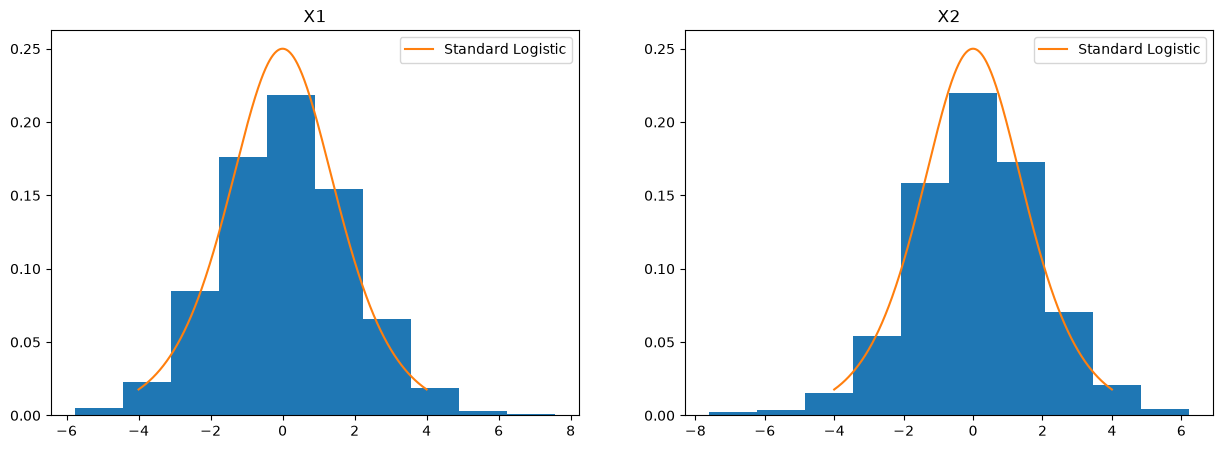

In [6]:
_, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].hist(Xtilde[:,0], density=True)
axes[0].plot(x, pdf, label="Standard Logistic")
axes[0].legend()
axes[0].set_title('X1')

axes[1].hist(Xtilde[:,1], density=True)
axes[1].plot(x, pdf, label="Standard Logistic")
axes[1].legend()
axes[1].set_title('X2')

plt.show()

In [7]:
def example2_normal(n=2000):
    U = torch.rand(n, 2)
    X = torch.distributions.Normal(0, 1).icdf(U)
    mg = MissingnessGenerator(U)
    M = mg.example2(U[:,0], U[:, 1])
    Xtest = torch.randn(n, 2) # N2(0,1)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [8]:
n_runs = 50

In [9]:
res = [example2_normal() for _ in range(50)]
res = np.array(res)

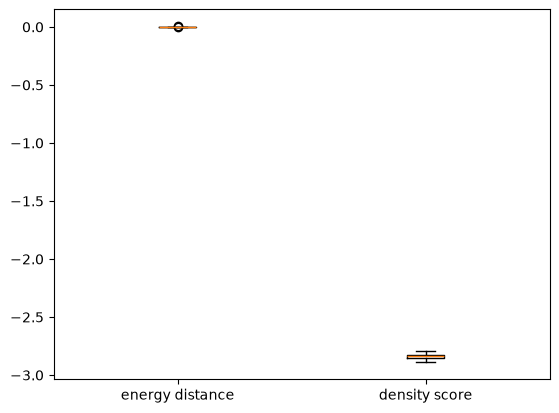

In [10]:
plt.boxplot(res, tick_labels=['energy distance', 'density score'])
plt.show()

In [11]:
n = 2000
U = torch.rand(n, 2)
X = torch.distributions.Normal(0, 1).icdf(U)
mg = MissingnessGenerator(U)
M = mg.example2(U[:,0], U[:, 1])
gmm = GaussianMixtureMAR(kk)
gmm.fit(X, M)

In [12]:
Xtilde = gmm.sample(n)[0]

In [13]:
from scipy.stats import norm
x = np.linspace(-4, 4, 500)

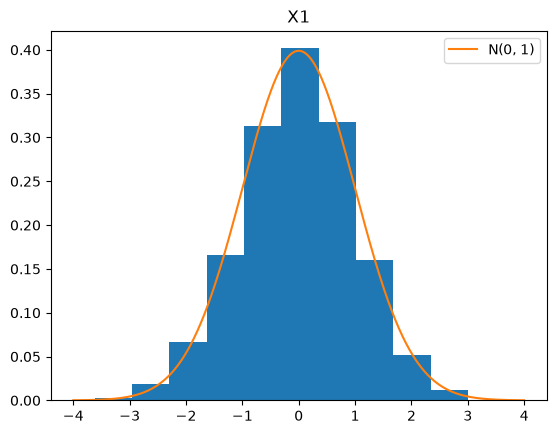

In [14]:
plt.hist(Xtilde[:,0], density=True)
plt.title('X1')
plt.plot(x, norm.pdf(x), label="N(0, 1)")
plt.legend()
plt.show()

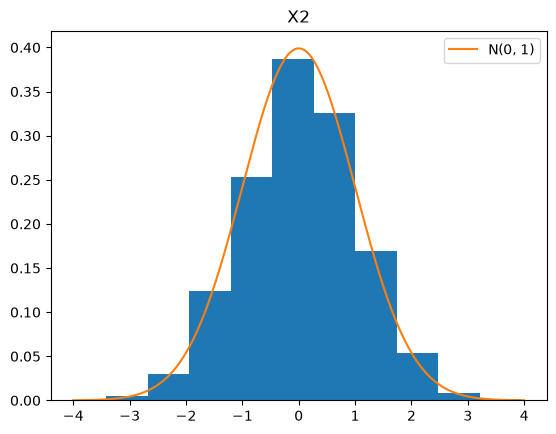

In [15]:
plt.hist(Xtilde[:,1], density=True)
plt.title('X2')
plt.plot(x, norm.pdf(x), label="N(0, 1)")
plt.legend()
plt.show()

In [16]:
# imputation

find the posterior mixture measure after observing $x^{(m)}$

$$
P(x^{(\bar m)} \mid x^{(m)}) = \sum_k \pi_k' P(x^{(\bar m)} \mid x^{(m)}, k) = \sum_k \pi_k' \frac{P(x \mid k)}{P(x^{m} \mid k)}
$$

$$
P(K = k \mid x^{(m)}) = \frac{P(x^{m} \mid K=k) \pi_k}{\sum_{j} P(x^{m} \mid K=j) \pi_j}
$$

In [22]:
pi, mu, sigma = gmm.best_params

In [25]:
p1 = gmm.best_model._estimate_log_prob(X, M)
post = p1 * pi[None, :, None]
post / post.sum(dim=1)[:, None, :]

tensor([[[0.6860, 0.7381],
         [0.3140, 0.2619]],

        [[   nan, 0.7824],
         [   nan, 0.2176]],

        [[0.6634,    nan],
         [0.3366,    nan]],

        ...,

        [[0.6827,    nan],
         [0.3173,    nan]],

        [[0.7069,    nan],
         [0.2931,    nan]],

        [[0.6979, 0.6558],
         [0.3021, 0.3442]]])

In [17]:
def sample_conditional_gmm(mu, sigma, pi, xa, a_idx, b_idx, n_samples=1):
    """
    Sample pn(xmb | xm)

    Parameters
    ----------
    mu : Tensor
        Shape (K, D), component means.
    sigma : Tensor
        Shape (K, D), component standard deviations.
    pi : Tensor
        Shape (K,), mixture weights, sum to 1.
    xa : Tensor
        Shape (Da,), observed Xa.
    a_idx : Tensor
        Indices of Xa dimensions.
    b_idx : Tensor
        Indices of Xb dimensions.
    n_samples : int
        Number of samples.

    Returns
    -------
    xb : Tensor
        Shape (n_samples, Db).
    posterior_pi : Tensor
        Shape (K,), p(K | Xa=xa).
    """

    # Parameters for Xa in each component
    mu_a = mu[:, a_idx]       # (K, Da)
    sigma_a = sigma[:, a_idx] # (K, Da)

    # log p(xa | K=k)
    dist_a = torch.distributions.Normal(mu_a, sigma_a)
    log_p_xa_given_k = dist_a.log_prob(xa).sum(dim=-1)  # (K,)

    # log p(K=k | xa) ∝ log pi_k + log p(xa | k)
    log_posterior = torch.log(pi) + log_p_xa_given_k

    # Numerically stable normalization
    posterior_pi = torch.softmax(log_posterior, dim=0)

    # Sample component indices
    k = torch.multinomial(
        posterior_pi,
        num_samples=n_samples,
        replacement=True
    )

    # Parameters of Xb for selected components
    mu_b = mu[k][:, b_idx]       # (n_samples, Db)
    sigma_b = sigma[k][:, b_idx] # (n_samples, Db)

    # Sample Xb | K
    xb = torch.distributions.Normal(mu_b, sigma_b).sample()

    return xb, posterior_pi